# Numerical mode evolution

*Numerical experiment.* Parameters are printed with each result.

All computations call `desitter_qft`; see the matching `docs/` file for derivations.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', 'src')))
import numpy as np, sympy as sp, matplotlib.pyplot as plt
from IPython.display import Image, display
from desitter_qft.plotting import apply_style; apply_style()
FIG = os.path.abspath(os.path.join('..', 'figures'))

In [2]:
from desitter_qft import experiments as ex
fm = ex.free_modes_experiment(n=300)
for n, r in fm.items(): print(f"{n:32s} max|v_num - v_ana| = {r['max_abs_err']:.2e}   max|W-i| = {r['wronskian_report']['max_residual']:.2e}")

conformal  (m=0, xi=1/6)         max|v_num - v_ana| = 4.18e-11   max|W-i| = 4.17e-11
massless minimal (m=0, xi=0)     max|v_num - v_ana| = 2.04e-09   max|W-i| = 4.50e-11
light massive (m=0.8H, xi=0)     max|v_num - v_ana| = 7.17e-10   max|W-i| = 4.34e-11
heavy (m=1.7H, xi=0)             max|v_num - v_ana| = 4.39e-11   max|W-i| = 5.59e-11


In [3]:
sw = ex.tolerance_sweep(rtols=(1e-4, 1e-6, 1e-8, 1e-10), methods=('DOP853',))
print('rtol  :', sw['rtols']); print('error :', sw['results']['DOP853']['err'])

rtol  : [1.e-04 1.e-06 1.e-08 1.e-10]
error : [7.93716092e-04 7.69003908e-06 7.81141865e-08 7.86397486e-10]


('massless minimal', 0) [2.36154636e-03 2.63013533e-05 6.89085925e-07 6.33947617e-09]
('massless minimal', 2) [6.38783301e-04 7.42894121e-07 2.90951729e-09 2.26529906e-12]
('massless minimal', 4) [3.84825912e-04 4.15105458e-08 2.57285304e-11 8.45212789e-13]


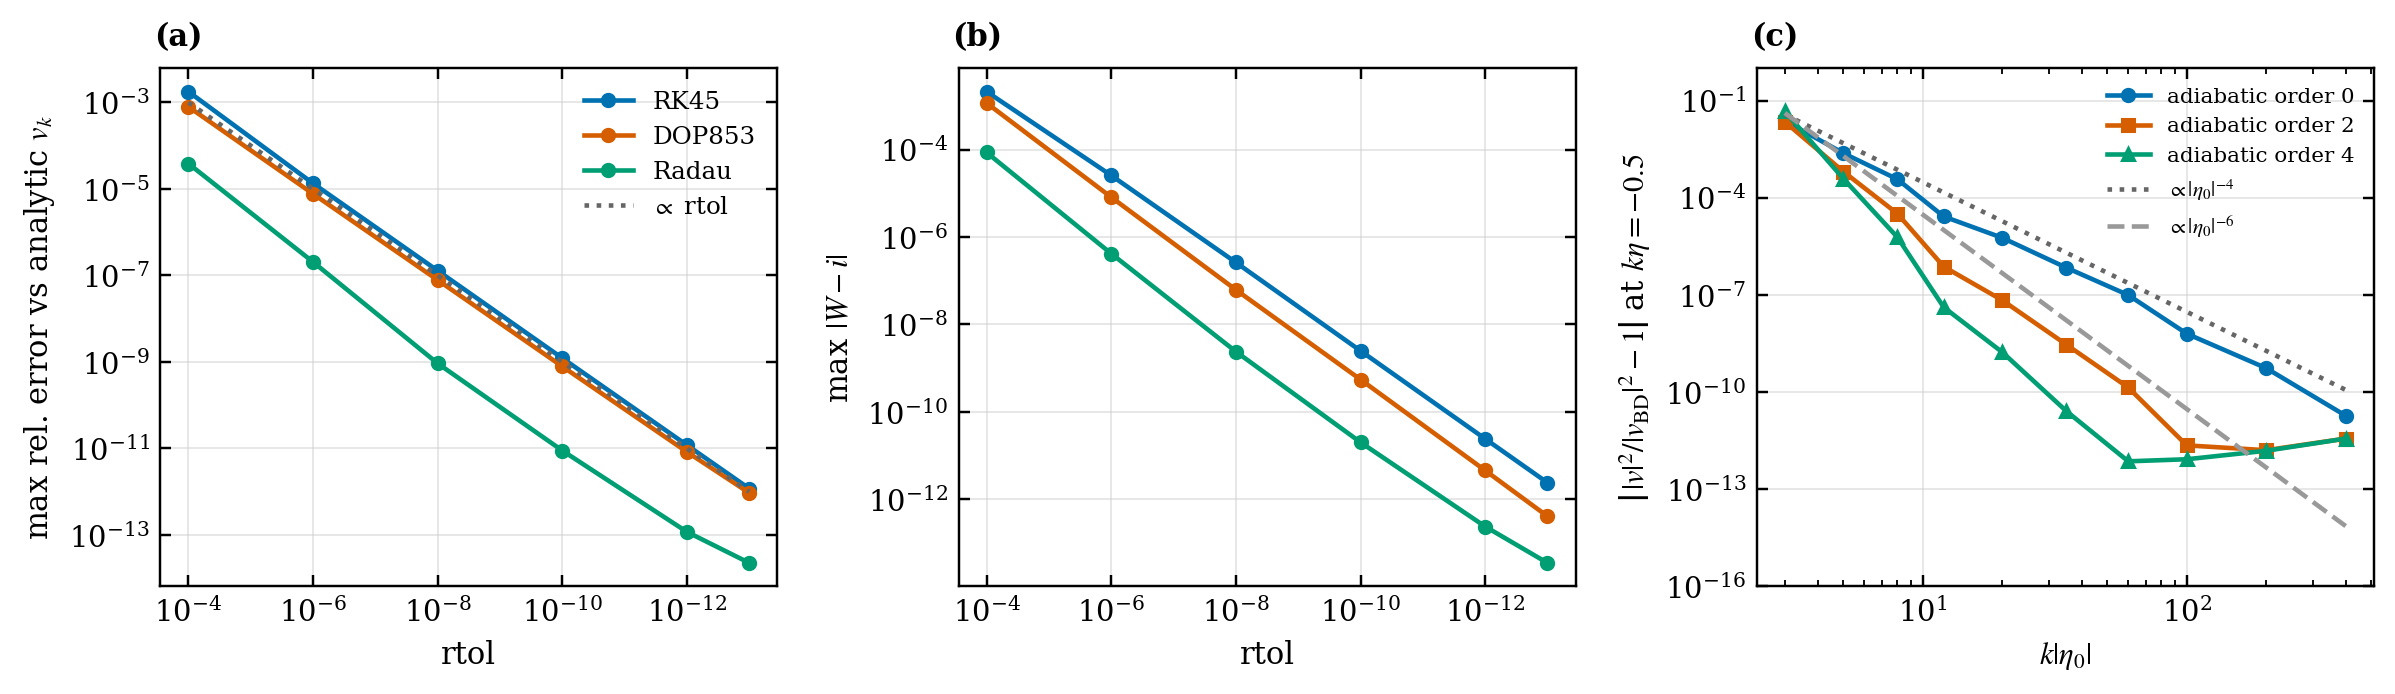

In [4]:
ad = ex.adiabatic_convergence(eta0s=np.array([-5., -12., -35., -100.]), orders=(0, 2, 4), cases=(('massless minimal', 0.0, 0.0),))
for k, e in ad['errors'].items(): print(k, e)
display(Image(os.path.join(FIG, 'fig03_solver_convergence_and_vacuum.png')))